In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("pandas:", pd.__version__)
print("numpy:", np.__version__)

pandas: 3.0.3
numpy: 2.4.6


In [4]:
PROJECT_DIR = Path("/Users/hyuna/OpenNeuro/ds007116")

PHENO_DIR = PROJECT_DIR / "phenotype"

print("PROJECT_DIR exists:", PROJECT_DIR.exists())
print("PHENO_DIR exists:", PHENO_DIR.exists())

PROJECT_DIR exists: True
PHENO_DIR exists: True


In [5]:
for p in sorted(PHENO_DIR.glob("*.tsv")):
    print(p.name)

age_differentiation_test.tsv
ales.tsv
als-18.tsv
ari.tsv
asrm.tsv
bdi_1a_ms_child.tsv
bisbas_child.tsv
delay_discounting_task.tsv
digit_symbol.tsv
effort_discounting_task.tsv
eswan_adhd.tsv
eswan_dmdd.tsv
mapssr.tsv
measured_emotion_differentiation_test.tsv
motor_praxis.tsv
panas.tsv
penn_abstraction_inhibition_working_memory_task.tsv
penn_conditional_exclusion_task.tsv
penn_emotion_recognition_task.tsv
penn_face_memory_test.tsv
penn_matrix_reasoning_test.tsv
penn_verbal_reasoning_test.tsv
penn_word_memory_test.tsv
post_scan_stai_state.tsv
ppa.tsv
pre_scan_stai.tsv
prime.tsv
risk_discounting_task.tsv
rpas.tsv
rsas.tsv
short_computerized_finger_tapping_task.tsv
short_letter_2back.tsv
short_penn_continuous_performance_test.tsv
substance.tsv
tanner_boy.tsv
tanner_girl.tsv
trailmaking_test_a.tsv
trailmaking_test_b.tsv
variable_short_penn_line_orientation_test.tsv
visual_object_learning_test.tsv
wolf_im_em.tsv


In [6]:
FEATURES = [
    "eswan_adhd_inattention_total",
    "eswan_adhd_hyperactivity_impulsivity_total",
    "bissc_total",
    "bas_total",
    "im_average",
    "em_average",
    "cnb_cptnl_total_sen",
    "cnb_cptnl_total_fp",
    "cnb_edisc_tot",
    "cnb_ddisc_tot",
    "cnb_rdisc_tot",
]

print("Number of clustering features:", len(FEATURES))

Number of clustering features: 11


In [7]:
eswan = pd.read_csv(
    PHENO_DIR / "eswan_adhd.tsv",
    sep="\t"
)

bisbas = pd.read_csv(
    PHENO_DIR / "bisbas_child.tsv",
    sep="\t"
)

wolf = pd.read_csv(
    PHENO_DIR / "wolf_im_em.tsv",
    sep="\t"
)

In [9]:
cpt = pd.read_csv(
    PHENO_DIR / "short_penn_continuous_performance_test.tsv",
    sep="\t"
)

effort = pd.read_csv(
    PHENO_DIR / "effort_discounting_task.tsv",
    sep="\t"
)

delay = pd.read_csv(
    PHENO_DIR / "delay_discounting_task.tsv",
    sep="\t"
)

risk = pd.read_csv(
    PHENO_DIR / "risk_discounting_task.tsv",
    sep="\t"
)

In [10]:
tables = {
    "E-SWAN": eswan,
    "BIS/BAS": bisbas,
    "IM/EM": wolf,
    "CPT": cpt,
    "Effort": effort,
    "Delay": delay,
    "Risk": risk,
}

for name, df in tables.items():
    print(f"\n{name}")
    print("shape:", df.shape)
    print("columns:")
    print(df.columns.tolist())


E-SWAN
shape: (223, 24)
columns:
['participant_id', 'session_id', 'eswan_adhd_01', 'eswan_adhd_02', 'eswan_adhd_03', 'eswan_adhd_04', 'eswan_adhd_05', 'eswan_adhd_06', 'eswan_adhd_07', 'eswan_adhd_08', 'eswan_adhd_09', 'eswan_adhd_10', 'eswan_adhd_11', 'eswan_adhd_12', 'eswan_adhd_13', 'eswan_adhd_14', 'eswan_adhd_15', 'eswan_adhd_16', 'eswan_adhd_17', 'eswan_adhd_18', 'eswan_adhd_proband_complete', 'eswan_adhd_inattention_total', 'eswan_adhd_hyperactivity_impulsivity_total', 'eswan_adhd_total_score']

BIS/BAS
shape: (223, 28)
columns:
['participant_id', 'session_id', 'bisbas_child_1', 'bisbas_child_2', 'bisbas_child_3', 'bisbas_child_4', 'bisbas_child_5', 'bisbas_child_6', 'bisbas_child_7', 'bisbas_child_8', 'bisbas_child_9', 'bisbas_child_10', 'bisbas_child_11', 'bisbas_child_12', 'bisbas_child_13', 'bisbas_child_14', 'bisbas_child_15', 'bisbas_child_16', 'bisbas_child_17', 'bisbas_child_18', 'bisbas_child_19', 'bisbas_child_20', 'behavioral_inhibitionactivation_system_child_versi_c

In [11]:
for name, df in tables.items():
    print(f"\n{name}")
    
    if "participant_id" in df.columns:
        print("participants:", df["participant_id"].nunique())
        
    if "session_id" in df.columns:
        print("sessions:")
        print(df["session_id"].value_counts(dropna=False).sort_index())


E-SWAN
participants: 132
sessions:
session_id
ses-1    132
ses-2     72
ses-3     19
Name: count, dtype: int64

BIS/BAS
participants: 132
sessions:
session_id
ses-1    132
ses-2     72
ses-3     19
Name: count, dtype: int64

IM/EM
participants: 132
sessions:
session_id
ses-1    132
ses-2     72
ses-3     19
Name: count, dtype: int64

CPT
participants: 131
sessions:
session_id
ses-1    130
ses-2     69
ses-3     20
Name: count, dtype: int64

Effort
participants: 131
sessions:
session_id
ses-1    130
ses-2     69
ses-3     20
Name: count, dtype: int64

Delay
participants: 131
sessions:
session_id
ses-1    130
ses-2     69
ses-3     20
Name: count, dtype: int64

Risk
participants: 131
sessions:
session_id
ses-1    130
ses-2     69
ses-3     20
Name: count, dtype: int64


In [12]:
wanted_by_table = {
    "E-SWAN": [
        "participant_id",
        "session_id",
        "eswan_adhd_inattention_total",
        "eswan_adhd_hyperactivity_impulsivity_total",
    ],
    
    "BIS/BAS": [
        "participant_id",
        "session_id",
        "bissc_total",
        "bas_total",
    ],
    
    "IM/EM": [
        "participant_id",
        "session_id",
        "im_average",
        "em_average",
    ],
    
    "CPT": [
        "participant_id",
        "session_id",
        "cnb_cptnl_total_sen",
        "cnb_cptnl_total_fp",
    ],
    
    "Effort": [
        "participant_id",
        "session_id",
        "cnb_edisc_tot",
    ],
    
    "Delay": [
        "participant_id",
        "session_id",
        "cnb_ddisc_tot",
    ],
    
    "Risk": [
        "participant_id",
        "session_id",
        "cnb_rdisc_tot",
    ],
}

for name, wanted in wanted_by_table.items():
    df = tables[name]
    
    print(f"\n{name}")
    for col in wanted:
        print(f"{col:45s}", col in df.columns)


E-SWAN
participant_id                                True
session_id                                    True
eswan_adhd_inattention_total                  True
eswan_adhd_hyperactivity_impulsivity_total    True

BIS/BAS
participant_id                                True
session_id                                    True
bissc_total                                   True
bas_total                                     True

IM/EM
participant_id                                True
session_id                                    True
im_average                                    True
em_average                                    True

CPT
participant_id                                True
session_id                                    True
cnb_cptnl_total_sen                           True
cnb_cptnl_total_fp                            True

Effort
participant_id                                True
session_id                                    True
cnb_edisc_tot                                

In [13]:
KEYS = ["participant_id", "session_id"]

analysis_df = (
    eswan[wanted_by_table["E-SWAN"]]
    .merge(
        bisbas[wanted_by_table["BIS/BAS"]],
        on=KEYS,
        how="outer"
    )
    .merge(
        wolf[wanted_by_table["IM/EM"]],
        on=KEYS,
        how="outer"
    )
    .merge(
        cpt[wanted_by_table["CPT"]],
        on=KEYS,
        how="outer"
    )
    .merge(
        effort[wanted_by_table["Effort"]],
        on=KEYS,
        how="outer"
    )
    .merge(
        delay[wanted_by_table["Delay"]],
        on=KEYS,
        how="outer"
    )
    .merge(
        risk[wanted_by_table["Risk"]],
        on=KEYS,
        how="outer"
    )
)

print("Merged shape:", analysis_df.shape)
print("Unique participants:", analysis_df["participant_id"].nunique())

analysis_df.head()

Merged shape: (224, 13)
Unique participants: 132


,participant_id,session_id,eswan_adhd_inattention_total,eswan_adhd_hyperactivity_impulsivity_total,bissc_total,bas_total,im_average,em_average,cnb_cptnl_total_sen,cnb_cptnl_total_fp,cnb_edisc_tot,cnb_ddisc_tot,cnb_rdisc_tot
0,sub-138950,ses-1,13.0,9.0,14.0,25.0,4.142857,5.333333,0.9000,13.0,62.0,10.0,20.0
1,sub-138950,ses-2,16.0,24.0,16.0,29.0,2.857143,4.166667,0.8667,6.0,74.0,14.0,25.0
2,sub-19861,ses-1,-5.0,-4.0,15.0,17.0,4.285714,4.833333,0.9500,2.0,57.0,6.0,36.0
3,sub-19861,ses-2,NaN,NaN,23.0,17.0,NaN,NaN,0.9833,2.0,60.0,3.0,22.0
4,sub-20124,ses-1,-17.0,-10.0,19.0,24.0,NaN,NaN,NaN,NaN,58.0,12.0,32.0


In [14]:
duplicates = analysis_df.duplicated(
    subset=["participant_id", "session_id"],
    keep=False
)

print("Duplicated participant-session rows:", duplicates.sum())

if duplicates.any():
    display(
        analysis_df.loc[
            duplicates,
            ["participant_id", "session_id"]
        ].sort_values(["participant_id", "session_id"])
    )

Duplicated participant-session rows: 0


In [15]:
missing_summary = pd.DataFrame({
    "n_missing": analysis_df[FEATURES].isna().sum(),
    "pct_missing": analysis_df[FEATURES].isna().mean() * 100
})

missing_summary = missing_summary.sort_values(
    "pct_missing",
    ascending=False
)

missing_summary

,n_missing,pct_missing
em_average,33,14.732143
im_average,29,12.946429
bas_total,20,8.928571
cnb_cptnl_total_sen,17,7.589286
cnb_cptnl_total_fp,17,7.589286
bissc_total,16,7.142857
eswan_adhd_hyperactivity_impulsivity_total,10,4.464286
cnb_edisc_tot,10,4.464286
cnb_ddisc_tot,10,4.464286
cnb_rdisc_tot,10,4.464286


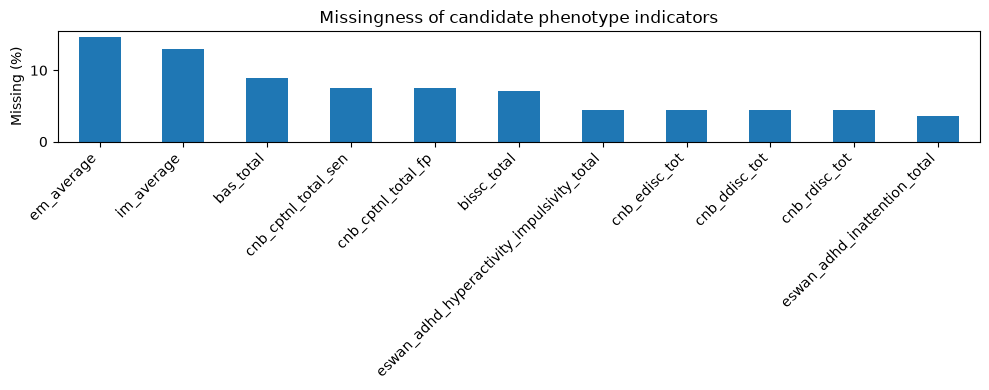

In [16]:
ax = missing_summary["pct_missing"].plot(
    kind="bar",
    figsize=(10, 4)
)

ax.set_ylabel("Missing (%)")
ax.set_xlabel("")
ax.set_title("Missingness of candidate phenotype indicators")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [17]:
OUTPUT_DIR = PROJECT_DIR / "derived"
OUTPUT_DIR.mkdir(exist_ok=True)

analysis_df.to_csv(
    OUTPUT_DIR / "phenotype_merged_long.csv",
    index=False
)

print("Saved:", OUTPUT_DIR / "phenotype_merged_long.csv")

Saved: /Users/hyuna/OpenNeuro/ds007116/derived/phenotype_merged_long.csv
